In [1]:
import sys, importlib, time 
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, 
                             confusion_matrix, ConfusionMatrixDisplay, 
                             classification_report)

PROJECT_ROOT=Path.cwd()
if PROJECT_ROOT.name=="notebooks":
    PROJECT_ROOT=PROJECT_ROOT.parent

sys.path.append(str(PROJECT_ROOT/"src"))

import data_loader,models,training,evaluation
for m in (data_loader,models,training,evaluation):
    importlib.reload(m)
from data_loader import create_binary_label
from models import ANNModel
from training import train_model
from evaluation import predict_model

Data_path=r"C:/Users/urvi_/Downloads/dataset.h5"
RESULTS =PROJECT_ROOT / "results"
figs=RESULTS/"figures"
figs.mkdir(parents=True,exist_ok=True)
cache=RESULTS/"features_all_days_v2.npz"

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device",device)

Device cuda


In [2]:
def build_feature_cache(data_path, out_path, chunk=1000, bad=(59,60,61)):
    with h5py.File(data_path,"r")as f:
        n,n_ch,n_bands=f["X"].shape
        keep=[c for c in range(n_ch) if c not in bad]
        feats=np.empty((n,n_bands),dtype=np.float32)
        for s in range(0,n,chunk):
            block=f["X"][s:s+chunk][:,keep,:]
            feats[s:s+chunk]=np.log10(block.max(axis=1)+1e-20)
            print(f"{min(s+chunk,n)}/{n}",end="\r")
        y=f["y"][:]
        dt=np.array([d.decode() if isinstance(d,bytes) else str(d) for d in f["datetimes"][:]])
    np.savez(out_path,X=feats,y=y,dt=dt)
    
if not cache.exists():
    t0=time.time()
    build_feature_cache(Data_path,cache)
    print("\n Build cache in", round(time.time()-t0),"seconds")
else:
    print("Cache already exists:",cache)

Cache already exists: c:\Users\urvi_\OneDrive - Adelaide University\Desktop\Sem2\ProgAIML2\Vessel_Detection_DAS\results\features_all_days_v2.npz


In [3]:
d=np.load(cache)
x_all=d["X"]
y_dist=d["y"]
y_all=create_binary_label(y_dist,threshold=1000)
day_of=np.array(pd.to_datetime(d["dt"]).date)
days_sorted=sorted(set(day_of))

print(x_all.shape,y_all.shape)
print("Days: ",len(days_sorted),days_sorted[0],"to",days_sorted[-1])

(74771, 300) (74771,)
Days:  10 2023-06-16 to 2023-06-25


In [4]:
overview=pd.DataFrame({
    "day":[str(x) for x in days_sorted],
    "windows":[int((day_of==x).sum()) for x in days_sorted],
    "near_pct":[round(100*y_all[day_of==x].mean(),1) for x in days_sorted],
})
print(overview)
overview.to_csv(RESULTS/"daily_overview.csv", index=False)

          day  windows   near_pct
0  2023-06-16     7898  35.799999
1  2023-06-17     8616  32.500000
2  2023-06-18     8616  31.799999
3  2023-06-19     8616  30.100000
4  2023-06-20     8616  36.500000
5  2023-06-21     7577  26.900000
6  2023-06-22     2464  39.599998
7  2023-06-23     8616  34.099998
8  2023-06-24     8616  35.000000
9  2023-06-25     5136  23.200001


In [ ]:

class VesselDetection(Dataset):
    def __init__(self,X,y):
        self.X=torch.tensor(X,dtype=torch.float32)
        self.y=torch.tensor(y,dtype=torch.float32)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.X[i],self.y[i]

In [6]:
def run_fold(test_day,epoch=100,lr=1e-3, batch=64, dropout=0.3,wd=1e-4,seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    
    i=days_sorted.index(test_day)
    val_day=days_sorted[(i+1)%len(days_sorted)]
    
    test_idx=np.where(day_of==test_day)[0]
    val_idx=np.where(day_of==val_day)[0]
    fit_idx=np.where((day_of!=test_day)&(day_of!=val_day))[0]
    
    ss=StandardScaler().fit(x_all[fit_idx])
    
    def make_loader(idx,shuffle):
        ds=VesselDetection(ss.transform(x_all[idx]),y_all[idx])
        return DataLoader(ds,batch_size=batch,shuffle=shuffle)
    
    train_loader=make_loader(fit_idx,True)
    val_loader=make_loader(val_idx,False)
    test_loader=make_loader(test_idx,False)
    
    n_far=(y_all[fit_idx]==0).sum()
    n_near=(y_all[fit_idx]==1).sum()
    criterion=nn.BCEWithLogitsLoss(pos_weight=torch.tensor([n_far/n_near],dtype=torch.float32).to(device))
    
    model=ANNModel(input_size=x_all.shape[1],hidden1=256,hidden2=128,dropout=dropout).to(device)
    optimizer=torch.optim.Adam(model.parameters(),lr=lr,weight_decay=wd)
    
    history=train_model(model,train_loader,criterion,optimizer,device,
                        epochs=epoch,val_loader=val_loader,patience=10)
    
    y_true,y_pred,y_prob=predict_model(model,test_loader,device)
    y_true=y_true.astype(int)
    y_pred=y_pred.astype(int).flatten()
    y_prob=y_prob.flatten()
    far_f1,near_f1=f1_score(y_true,y_pred,average=None,zero_division=0)
    
    metrics={
        "test_day":str(test_day),
        "val_day":str(val_day),
        "n_train":len(fit_idx),
        "n_val":len(val_idx),
        "n_test":len(test_idx),
        "best_epoch":int(np.argmin(history["val_loss"]))+1,
        "epochs_run":len(history["train_loss"]),
        "accuracy":accuracy_score(y_true,y_pred),
        "weighted_f1":f1_score(y_true,y_pred,average="weighted",zero_division=0),
        "far_f1":far_f1,
        "near_f1":near_f1,
        "auc":roc_auc_score(y_true,y_prob)
    }
    
    return metrics,history,(y_true,y_pred,y_prob)

In [8]:
results,histories,pooled=[],{},[]
t_all=time.time()

for day in days_sorted:
    t0=time.time()
    print(f"\n === Test day {day} ===")
    r,h,preds=run_fold(day)
    results.append(r)
    histories[str(day)]=h
    pooled.append((str(day),*preds))
    pd.DataFrame(results).to_csv(RESULTS/"ann_v2_10day_partial.csv",index=False)
    print({k:(round(v,4) if isinstance(v,float) else v)for k,v in r.items()})
    print(f"Fold time: {round(time.time()-t0)}s")
    
print("\n Total time (min):", round((time.time()-t_all)/60,1))



 === Test day 2023-06-16 ===
Epoch 1/100 | Train loss: 0.4467 | Val loss: 0.3979
Epoch 2/100 | Train loss: 0.3918 | Val loss: 0.4071
Epoch 3/100 | Train loss: 0.3715 | Val loss: 0.3926
Epoch 4/100 | Train loss: 0.3574 | Val loss: 0.3774
Epoch 5/100 | Train loss: 0.3453 | Val loss: 0.3852
Epoch 6/100 | Train loss: 0.3381 | Val loss: 0.4019
Epoch 7/100 | Train loss: 0.3277 | Val loss: 0.4171
Epoch 8/100 | Train loss: 0.3207 | Val loss: 0.4101
Epoch 9/100 | Train loss: 0.3110 | Val loss: 0.4143
Epoch 10/100 | Train loss: 0.3093 | Val loss: 0.3859
Epoch 11/100 | Train loss: 0.2951 | Val loss: 0.3772
Epoch 12/100 | Train loss: 0.2972 | Val loss: 0.4489
Epoch 13/100 | Train loss: 0.2913 | Val loss: 0.3974
Epoch 14/100 | Train loss: 0.2847 | Val loss: 0.3991
Epoch 15/100 | Train loss: 0.2784 | Val loss: 0.4340
Epoch 16/100 | Train loss: 0.2777 | Val loss: 0.4309
Epoch 17/100 | Train loss: 0.2746 | Val loss: 0.3834
Epoch 18/100 | Train loss: 0.2673 | Val loss: 0.3937
Epoch 19/100 | Train loss

In [9]:
df=pd.DataFrame(results)
metric_cols=["accuracy","weighted_f1","far_f1","near_f1","auc"]

print(df[["test_day","val_day","n_test","best_epoch","epochs_run"]+metric_cols].round(4))
summary=df[metric_cols].agg(["mean","std"]).round(4)
print("\n", summary)

df["model"]="ANN"
df["split"]="leave_one_day_out_10days"
df.to_csv(RESULTS/"tables"/"ann_10day_results.csv",index=False)
summary.to_csv(RESULTS/"tables"/"ann_10day_summary.csv")

     test_day     val_day  n_test  best_epoch  epochs_run  accuracy  \
0  2023-06-16  2023-06-17    7898          11          21    0.8706   
1  2023-06-17  2023-06-18    8616           3          13    0.9022   
2  2023-06-18  2023-06-19    8616           1          11    0.8702   
3  2023-06-19  2023-06-20    8616           8          18    0.8860   
4  2023-06-20  2023-06-21    8616           9          19    0.8719   
5  2023-06-21  2023-06-22    7577           2          12    0.9205   
6  2023-06-22  2023-06-23    2464           2          12    0.7500   
7  2023-06-23  2023-06-24    8616           9          19    0.8851   
8  2023-06-24  2023-06-25    8616           6          16    0.8799   
9  2023-06-25  2023-06-16    5136           4          14    0.9379   

   weighted_f1  far_f1  near_f1     auc  
0       0.8709  0.8986   0.8214  0.9243  
1       0.9019  0.9278   0.8481  0.9458  
2       0.8730  0.9001   0.8150  0.9438  
3       0.8838  0.9206   0.7982  0.9154  
4       

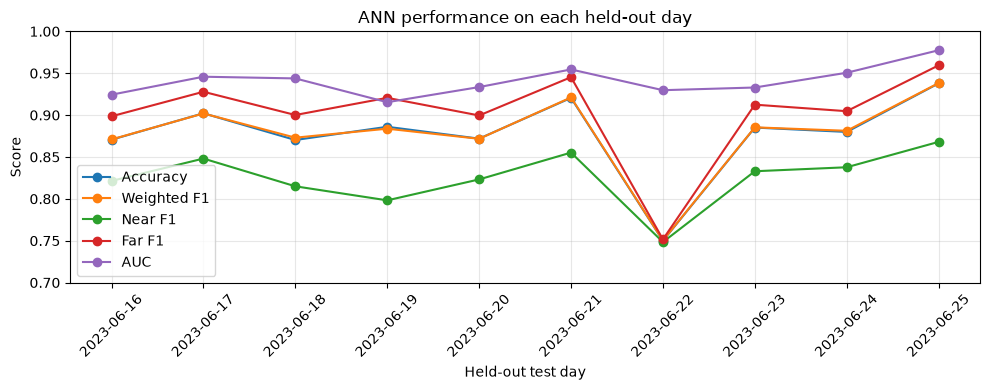

In [10]:
plt.figure(figsize=(10,4))
for col,lab in [("accuracy","Accuracy"),("weighted_f1","Weighted F1"),
                ("near_f1","Near F1"),("far_f1","Far F1"),("auc","AUC")]:
    plt.plot(df["test_day"],df[col],marker="o",label=lab)
plt.xticks(rotation=45)
plt.ylim(0.7,1.0)
plt.xlabel("Held-out test day")
plt.ylabel("Score")
plt.title("ANN performance on each held-out day")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(figs/"ann_10day_per_fold.png",dpi=300,bbox_inches="tight")
plt.show()

[[45581  4940]
 [ 3691 20559]]
               precision    recall  f1-score   support

Far (>=1000m)     0.9251    0.9022    0.9135     50521
Near (<1000m)     0.8063    0.8478    0.8265     24250

     accuracy                         0.8846     74771
    macro avg     0.8657    0.8750    0.8700     74771
 weighted avg     0.8866    0.8846    0.8853     74771



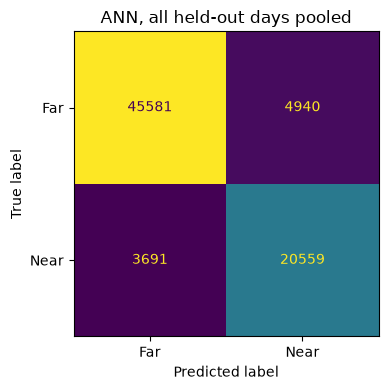

In [11]:
yt=np.concatenate([p[1] for p in pooled])
yp=np.concatenate([p[2] for p in pooled])
pr=np.concatenate([p[3] for p in pooled])
days_col=np.concatenate([[p[0]]*len(p[1]) for p in pooled])

cm=confusion_matrix(yt,yp)
print(cm)
print(classification_report(yt,yp,target_names=["Far (>=1000m)","Near (<1000m)"],digits=4))

fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay(cm,display_labels=["Far","Near"]).plot(ax=ax,colorbar=False,values_format="d")
ax.set_title("ANN, all held-out days pooled")
plt.tight_layout()
plt.savefig(figs/"ann_10day_confusion_matric.png",dpi=300,bbox_inches="tight")
plt.show()

pd.DataFrame({"test_day":days_col,"true":yt,"pred":yp,"prob":pr}).to_csv(RESULTS/"tables"/"ann_10day_predictions.csv",index=False)


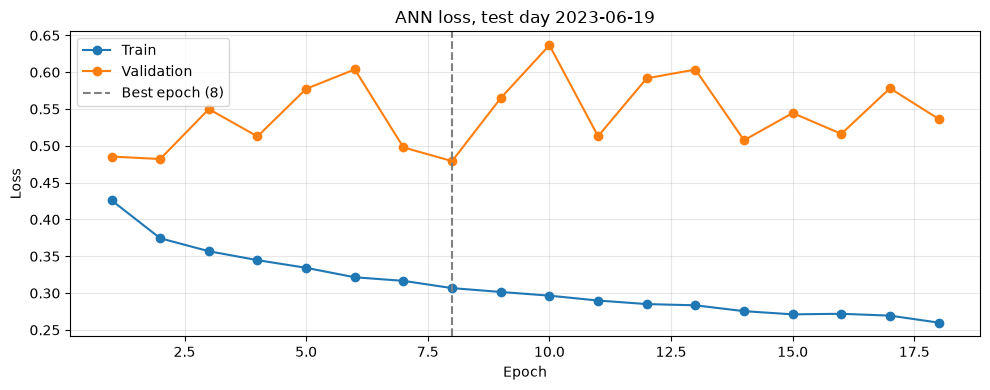

In [12]:
day="2023-06-19"
h=histories[day]
n=len(h["train_loss"])
best=int(np.argmin(h["val_loss"]))+1

plt.figure(figsize=(10,4))
plt.plot(range(1,n+1),h["train_loss"],marker="o",label="Train")
plt.plot(range(1,n+1),h["val_loss"],marker="o",label="Validation")
plt.axvline(best,linestyle="--",color="gray",label=f"Best epoch ({best})")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"ANN loss, test day {day}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(figs/"ann_10day_loss_example.png", dpi=300, bbox_inches="tight")
plt.show()

In [13]:
old = pd.read_csv(RESULTS / "ann_10day_results.csv")
new = pd.DataFrame(results)
cols = ["accuracy", "weighted_f1", "far_f1", "near_f1", "auc"]
print(pd.concat([old[cols].mean(), new[cols].mean()], axis=1,
                keys=["max only, 100 features", "max, mean, p90, 300 features"]).round(4))
print("days with higher near F1:", (new["near_f1"].values > old["near_f1"].values).sum(), "of 10")

             max only, 100 features  max, mean, p90, 300 features
accuracy                     0.8758                        0.8774
weighted_f1                  0.8762                        0.8778
far_f1                       0.9030                        0.9020
near_f1                      0.8180                        0.8248
auc                          0.9379                        0.9408
days with higher near F1: 8 of 10


In [17]:
print(len(results), len(pooled))

10 10


In [ ]:
df = pd.DataFrame(results)
df["model"] = "ANN_v2"; df["split"] = "leave_one_day_out_10days_300features"
df.to_csv(RESULTS / "ann_v2_10day_results.csv", index=False)

yt = np.concatenate([x[1] for x in pooled])
yp = np.concatenate([x[2] for x in pooled])
pr = np.concatenate([x[3] for x in pooled])
dc = np.concatenate([[x[0]] * len(x[1]) for x in pooled])
pd.DataFrame({"test_day": dc, "true": yt, "pred": yp, "prob": pr}).to_csv(
    RESULTS / "ann_v2_10day_predictions.csv", index=False)
print(len(yt))               

74771


In [22]:
with h5py.File(Data_path, "r") as f:
    vt = np.array([x.decode() if isinstance(x, bytes) else str(x) for x in f["ship_info"]["type"][:]])
    vt = np.char.lower(vt)
    order = np.concatenate([np.where(day_of == day)[0] for day in days_sorted])
    pp = pd.read_csv(RESULTS /"ann_v2_10day_predictions.csv")
    assert len(order) == len(pp) and (y_all[order] == pp["true"].values).all()   # confirms the alignment
    pp["vessel_type"] = vt[order]
    near = pp[pp["true"] == 1]
    tab = near.groupby("vessel_type").agg(n=("true", "size"), recall=("pred", "mean"))
    print(tab[tab.n >= 300].sort_values("recall").round(3))

                                 n  recall
vessel_type                               
hopper dredger                2582   0.662
fishing vessel                 439   0.663
general cargo ship            1719   0.663
lpg tanker                     951   0.875
bulk carrier                  1618   0.883
unknown                        882   0.898
vehicles carrier              2022   0.908
chemical/oil products tanker  3712   0.916
ro-ro cargo ship              3777   0.924
container ship                4316   0.951


In [24]:
with h5py.File(Data_path, "r") as f:
    ln = f["ship_info"]["length"][:].astype(float)
pp["length"] = ln[order]
near = pp[pp["true"] == 1].copy()
near["size"] = pd.cut(near["length"], [0, 50, 100, 150, 200, 1000],
                      labels=["<50 m", "50-100 m", "100-150 m", "150-200 m", ">200 m"])
print(near.groupby("size", observed=True).agg(n=("true", "size"), recall=("pred", "mean")).round(3))

              n  recall
size                   
<50 m       896   0.512
50-100 m   2496   0.570
100-150 m  5643   0.798
150-200 m  7820   0.929
>200 m     6448   0.939


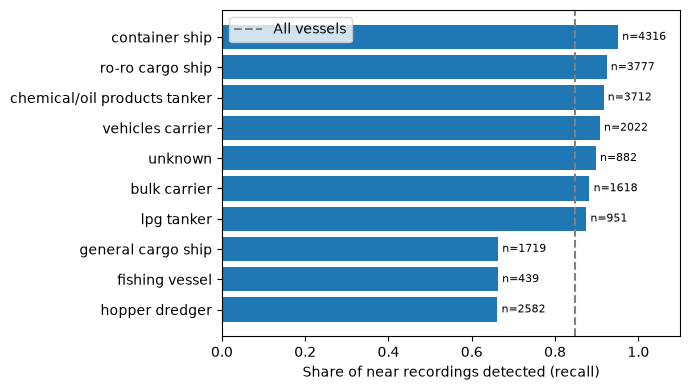

In [25]:
t = tab[tab.n >= 300].sort_values("recall")
plt.figure(figsize=(7, 4))
plt.barh(t.index, t["recall"])
plt.axvline(near["pred"].mean(), linestyle="--", color="gray", label="All vessels")
for i, (r, n) in enumerate(zip(t["recall"], t["n"])):
    plt.text(r + 0.01, i, f"n={n}", va="center", fontsize=8)
plt.xlim(0, 1.1); plt.xlabel("Share of near recordings detected (recall)")
plt.legend(); plt.tight_layout()
plt.savefig(RESULTS / "figures" / "ann_v2_recall_by_vessel_type.png", dpi=300)
plt.show()

In [26]:
with h5py.File(Data_path, "r") as f:                       # use Data_path if that's your name
    length = f["ship_info"]["length"][:].astype(float)
small = length < 100                                       # unknown lengths count as not small

class WDataset(Dataset):
    def __init__(self, X, y, w):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.t = torch.tensor(np.stack([y, w], axis=1), dtype=torch.float32)
    def __len__(self): return len(self.t)
    def __getitem__(self, i): return self.X[i], self.t[i]

class WeightedBCE(nn.Module):
    def forward(self, logits, target):                     # target columns: label, weight
        y, w = target[:, 0], target[:, 1]
        loss = nn.functional.binary_cross_entropy_with_logits(logits, y, reduction="none")
        return (loss * w).sum() / w.sum()

In [27]:
def run_fold_w(test_day, small_w=3.0, epochs=100, lr=1e-3, batch=64, dropout=0.3, wd=1e-4, seed=42):
    torch.manual_seed(seed); np.random.seed(seed)
    i = days_sorted.index(test_day)
    val_day = days_sorted[(i + 1) % len(days_sorted)]
    test_idx = np.where(day_of == test_day)[0]
    val_idx = np.where(day_of == val_day)[0]
    fit_idx = np.where((day_of != test_day) & (day_of != val_day))[0]

    ss = StandardScaler().fit(x_all[fit_idx])
    pos_w = (y_all[fit_idx] == 0).sum() / (y_all[fit_idx] == 1).sum()

    def weights(idx):
        y = y_all[idx]
        return np.where(y == 1, pos_w, 1.0) * np.where((y == 1) & small[idx], small_w, 1.0)

    def loader(idx, weighted, shuffle):
        X = ss.transform(x_all[idx])
        ds = WDataset(X, y_all[idx], weights(idx)) if weighted else VesselDetection(X, y_all[idx])
        return DataLoader(ds, batch_size=batch, shuffle=shuffle)

    train_loader, val_loader, test_loader = loader(fit_idx, True, True), loader(val_idx, True, False), loader(test_idx, False, False)
    model = ANNModel(input_size=x_all.shape[1], hidden1=256, hidden2=128, dropout=dropout).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    history = train_model(model, train_loader, WeightedBCE(), optimizer, device,
                          epochs=epochs, val_loader=val_loader, patience=10)

    y_true, y_pred, y_prob = predict_model(model, test_loader, device)
    y_true = y_true.astype(int); y_pred = y_pred.astype(int).flatten(); y_prob = y_prob.flatten()
    far_f1, near_f1 = f1_score(y_true, y_pred, average=None, zero_division=0)
    return {"test_day": str(test_day), "best_epoch": int(np.argmin(history["val_loss"])) + 1,
            "accuracy": accuracy_score(y_true, y_pred),
            "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
            "far_f1": far_f1, "near_f1": near_f1, "auc": roc_auc_score(y_true, y_prob)}, (y_true, y_pred, y_prob)

In [28]:
results_w, pooled_w = [], []
for day in days_sorted:
    r, preds = run_fold_w(day, small_w=3.0)
    results_w.append(r); pooled_w.append((str(day), *preds))
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()})

pd.DataFrame(results_w).to_csv(RESULTS / "ann_v2_smallw3_results.csv", index=False)
yt = np.concatenate([x[1] for x in pooled_w]); yp = np.concatenate([x[2] for x in pooled_w])
pr = np.concatenate([x[3] for x in pooled_w]); dc = np.concatenate([[x[0]] * len(x[1]) for x in pooled_w])
pd.DataFrame({"test_day": dc, "true": yt, "pred": yp, "prob": pr}).to_csv(
    RESULTS / "ann_v2_smallw3_predictions.csv", index=False)
print(len(yt))

Epoch 1/100 | Train loss: 0.3992 | Val loss: 0.3143
Epoch 2/100 | Train loss: 0.3509 | Val loss: 0.3406
Epoch 3/100 | Train loss: 0.3351 | Val loss: 0.2927
Epoch 4/100 | Train loss: 0.3244 | Val loss: 0.2986
Epoch 5/100 | Train loss: 0.3125 | Val loss: 0.2726
Epoch 6/100 | Train loss: 0.3062 | Val loss: 0.2850
Epoch 7/100 | Train loss: 0.2972 | Val loss: 0.2834
Epoch 8/100 | Train loss: 0.2928 | Val loss: 0.2869
Epoch 9/100 | Train loss: 0.2892 | Val loss: 0.2894
Epoch 10/100 | Train loss: 0.2862 | Val loss: 0.2931
Epoch 11/100 | Train loss: 0.2741 | Val loss: 0.3013
Epoch 12/100 | Train loss: 0.2742 | Val loss: 0.2787
Epoch 13/100 | Train loss: 0.2698 | Val loss: 0.2943
Epoch 14/100 | Train loss: 0.2643 | Val loss: 0.3615
Epoch 15/100 | Train loss: 0.2630 | Val loss: 0.2895
Early stopping at epoch 15
{'test_day': '2023-06-16', 'best_epoch': 5, 'accuracy': 0.8459, 'weighted_f1': 0.8483, 'far_f1': np.float64(0.8729), 'near_f1': np.float64(0.8043), 'auc': 0.9272}
Epoch 1/100 | Train loss

In [29]:
import joblib

def train_demo(test_day, seed=42):
    torch.manual_seed(seed); np.random.seed(seed)
    i = days_sorted.index(test_day)
    val_day = days_sorted[(i + 1) % len(days_sorted)]
    val_idx = np.where(day_of == val_day)[0]
    fit_idx = np.where((day_of != test_day) & (day_of != val_day))[0]
    ss = StandardScaler().fit(x_all[fit_idx])
    mk = lambda idx, sh: DataLoader(VesselDetection(ss.transform(x_all[idx]), y_all[idx]),
                                    batch_size=64, shuffle=sh)
    n_far, n_near = (y_all[fit_idx] == 0).sum(), (y_all[fit_idx] == 1).sum()
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([n_far / n_near], dtype=torch.float32).to(device))
    model = ANNModel(input_size=x_all.shape[1], hidden1=256, hidden2=128, dropout=0.3).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    train_model(model, mk(fit_idx, True), crit, opt, device, epochs=100, val_loader=mk(val_idx, False), patience=10)
    return model, ss

model, ss = train_demo(days_sorted[8])      
models_dir = RESULTS / "models"; models_dir.mkdir(exist_ok=True)
torch.save(model.state_dict(), models_dir / "ann_v2_demo_test0624.pth")
joblib.dump(ss, models_dir / "ann_v2_demo_scaler_test0624.pkl")
print("saved")

Epoch 1/100 | Train loss: 0.4522 | Val loss: 0.2821
Epoch 2/100 | Train loss: 0.4033 | Val loss: 0.2579
Epoch 3/100 | Train loss: 0.3863 | Val loss: 0.2521
Epoch 4/100 | Train loss: 0.3760 | Val loss: 0.2663
Epoch 5/100 | Train loss: 0.3610 | Val loss: 0.2672
Epoch 6/100 | Train loss: 0.3539 | Val loss: 0.2408
Epoch 7/100 | Train loss: 0.3449 | Val loss: 0.2613
Epoch 8/100 | Train loss: 0.3399 | Val loss: 0.2662
Epoch 9/100 | Train loss: 0.3327 | Val loss: 0.2583
Epoch 10/100 | Train loss: 0.3265 | Val loss: 0.2682
Epoch 11/100 | Train loss: 0.3169 | Val loss: 0.2705
Epoch 12/100 | Train loss: 0.3127 | Val loss: 0.2674
Epoch 13/100 | Train loss: 0.3072 | Val loss: 0.2836
Epoch 14/100 | Train loss: 0.3055 | Val loss: 0.2798
Epoch 15/100 | Train loss: 0.2969 | Val loss: 0.2673
Epoch 16/100 | Train loss: 0.2931 | Val loss: 0.3036
Early stopping at epoch 16
saved
